# ДЗ 7.1 — Остывание стержня (зелёный + жёлтый уровни)

Решаем одномерное уравнение теплопроводности:
$$u_t = u_{xx}, \qquad x \in [0, 1], \quad t > 0.$$

Граничные условия: $u(0,t) = u(1,t) = 0$.

**Зелёный уровень:** Начальное условие $u(x,0) = \sin(\pi x) + 0.3\sin(5\pi x)$.
Точное решение:
$$u(x,t) = e^{-\pi^2 t}\sin(\pi x) + 0.3e^{-25\pi^2 t}\sin(5\pi x).$$

**Жёлтый уровень:** Начальное условие — нагретый участок (ступенька): $u=1$ при $0.4 \le x \le 0.6$, вне его $u=0$.

Для дискретизации введем параметр $r = \Delta t / \Delta x^2$. 
При сгущении сетки для проверки порядка сходимости будем сохранять $r$ постоянным, то есть $\Delta t \sim \Delta x^2$.

## Инфраструктура и схемы

Для неявных схем (Эйлер и Кранка-Николсон) будем использовать разряженные матрицы (`scipy.sparse`) и решать систему линейных уравнений методом прогонки (`spsolve`).

Внутренние узлы: $j=1,\dots,N-1$ (где $N$ — число интервалов $\Delta x = 1/N$). 
Граничные узлы $u_0 = u_N = 0$ не входят в систему.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla

# ---------- Точное решение ----------
def exact_solution_smooth(x, t):
    return np.exp(-np.pi**2 * t) * np.sin(np.pi * x) + \
           0.3 * np.exp(-25 * np.pi**2 * t) * np.sin(5 * np.pi * x)

# ---------- Начальные условия ----------
def u0_smooth(x):
    return np.sin(np.pi * x) + 0.3 * np.sin(5 * np.pi * x)

def u0_step(x):
    # Жёлтый уровень: ступенька на [0.4, 0.6]
    return np.where((x >= 0.4) & (x <= 0.6), 1.0, 0.0)

# ---------- Сетка ----------
def make_grid(N):
    x = np.linspace(0, 1, N+1)
    dx = 1.0 / N
    return x, dx

# ---------- Матрицы для неявных схем ----------
def get_matrices(N, r):
    """
    Возвращает матрицы A и B для внутренних узлов.
    Для неявного Эйлера: A * u^{n+1} = u^n
    Для Кранка-Николсона: A * u^{n+1} = B * u^n
    """
    # Диагонали для оператора второй разности (с минусом)
    main_diag = 2 * np.ones(N-1)
    off_diag = -1 * np.ones(N-2)
    
    # Матрица для левой части (неявная)
    # (I - r * D2) * u^{n+1}
    A_impl = sp.diags([-r*off_diag, 1 + 2*r*main_diag, -r*off_diag], 
                      offsets=[-1, 0, 1], format='csc')
    
    # Матрица для правой части (Кранк-Николсон)
    # (I + 0.5*r * D2) * u^n
    B_cn = sp.diags([0.5*r*off_diag, 1 - r*main_diag, 0.5*r*off_diag], 
                    offsets=[-1, 0, 1], format='csc')
    
    return A_impl, B_cn

## Функции шага по времени

- **FTCS (Явная):** $u_j^{n+1} = u_j^n + r(u_{j+1}^n - 2u_j^n + u_{j-1}^n)$. Устойчива только при $r \le 0.5$.

- **Неявный Эйлер:** $(I - r D_2)u^{n+1} = u^n$. Безусловно устойчив, первый порядок по времени.

- **Кранк-Николсон:** $(I - \frac{r}{2} D_2)u^{n+1} = (I + \frac{r}{2} D_2)u^n$. Безусловно устойчив, второй порядок по времени.

In [2]:
def solve_heat(N, T_final, r, method='FTCS', u0_func=u0_smooth):
    x, dx = make_grid(N)
    dt = r * dx**2
    u = u0_func(x)
    
    if method == 'FTCS':
        # Векторизованный явный шаг
        def step(u):
            unew = u.copy()
            unew[1:-1] = u[1:-1] + r * (u[2:] - 2*u[1:-1] + u[:-2])
            return unew
    else:
        A, B = get_matrices(N, r)
        if method == 'Euler':
            def step(u):
                unew = u.copy()
                unew[1:-1] = spla.spsolve(A, u[1:-1])
                return unew
        elif method == 'CN':
            def step(u):
                unew = u.copy()
                rhs = B.dot(u[1:-1])
                unew[1:-1] = spla.spsolve(A, rhs)
                return unew
    
    t = 0.0
    history = [(t, u.copy())]
    while t < T_final - 1e-14:
        dt_step = min(dt, T_final - t)
        # Для последнего шага пересчитываем эффективное r
        if dt_step < dt:
            r_step = dt_step / dx**2
            if method == 'FTCS':
                # Переписываем step для локального r_step
                unew = u.copy()
                unew[1:-1] = u[1:-1] + r_step * (u[2:] - 2*u[1:-1] + u[:-2])
                u = unew
            else:
                A_step, B_step = get_matrices(N, r_step)
                if method == 'Euler':
                    u[1:-1] = spla.spsolve(A_step, u[1:-1])
                elif method == 'CN':
                    u[1:-1] = spla.spsolve(A_step, B_step.dot(u[1:-1]))
        else:
            u = step(u)
        t += dt_step
        history.append((t, u.copy()))
        
    return x, history

## Зелёный уровень — Гладкий профиль

Сравниваем FTCS и Неявный Эйлер при $r=0.4$ на сетках $N=25, 50, 100$ 
в моменты $t = 0.001, 0.01, 0.1$. Оцениваем порядок сходимости $E_\infty$.

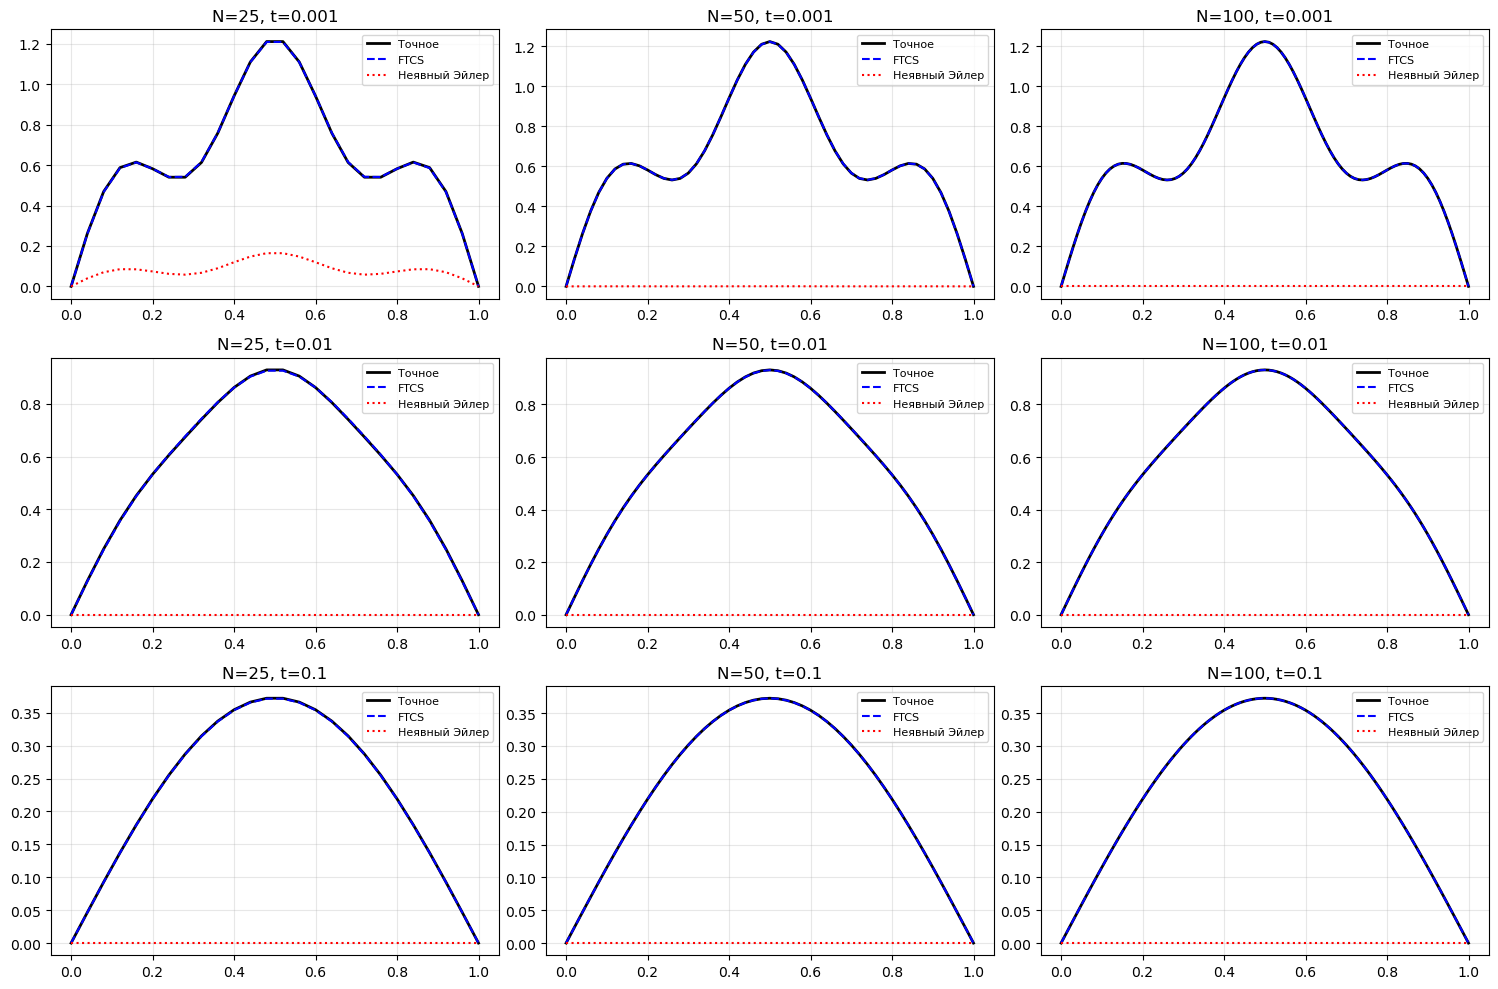

Максимальная ошибка E_inf (FTCS):
t=0.001: N=25: 1.99e-03 | N=50: 6.48e-04 | N=100: 1.68e-04
t=0.01: N=25: 2.90e-03 | N=50: 7.62e-04 | N=100: 1.91e-04
t=0.1: N=25: 6.76e-04 | N=50: 1.70e-04 | N=100: 4.24e-05

Максимальная ошибка E_inf (Неявный Эйлер):
t=0.001: N=25: 1.05e+00 | N=50: 1.22e+00 | N=100: 1.22e+00
t=0.01: N=25: 9.28e-01 | N=50: 9.31e-01 | N=100: 9.31e-01
t=0.1: N=25: 3.72e-01 | N=50: 3.73e-01 | N=100: 3.73e-01


In [3]:
N_list = [25, 50, 100]
t_vals = [0.001, 0.01, 0.1]
r = 0.4

fig, axes = plt.subplots(len(t_vals), len(N_list), figsize=(15, 10))
errors_ftcs = np.zeros((len(t_vals), len(N_list)))
errors_euler = np.zeros((len(t_vals), len(N_list)))

for i, T in enumerate(t_vals):
    for j, N in enumerate(N_list):
        x, dx = make_grid(N)
        u_ex = exact_solution_smooth(x, T)
        
        _, h_ftcs = solve_heat(N, T, r, 'FTCS')
        _, h_eul  = solve_heat(N, T, r, 'Euler')
        
        u_ftcs = h_ftcs[-1][1]
        u_eul  = h_eul[-1][1]
        
        errors_ftcs[i, j] = np.max(np.abs(u_ftcs - u_ex))
        errors_euler[i, j] = np.max(np.abs(u_eul - u_ex))
        
        ax = axes[i, j]
        ax.plot(x, u_ex, 'k-', lw=2, label='Точное')
        ax.plot(x, u_ftcs, 'b--', label='FTCS')
        ax.plot(x, u_eul, 'r:', label='Неявный Эйлер')
        ax.set_title(f"N={N}, t={T}")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Вывод таблиц
print("Максимальная ошибка E_inf (FTCS):")
for i, T in enumerate(t_vals):
    print(f"t={T}: " + " | ".join([f"N={N}: {errors_ftcs[i,j]:.2e}" for j, N in enumerate(N_list)]))

print("\nМаксимальная ошибка E_inf (Неявный Эйлер):")
for i, T in enumerate(t_vals):
    print(f"t={T}: " + " | ".join([f"N={N}: {errors_euler[i,j]:.2e}" for j, N in enumerate(N_list)]))

## Оценка порядка сходимости

При сгущении сетки в 2 раза ($N \to 2N$) ошибка должна уменьшаться как $2^p$, где $p$ — порядок сходимости.

In [4]:
print("Оценка порядка сходимости (по сеткам N=25 и N=50):")
for T_idx, T in enumerate(t_vals):
    p_ftcs = np.log2(errors_ftcs[T_idx, 0] / errors_ftcs[T_idx, 1])
    # Для Эйлера считаем порядок только там, где он вышел на режим
    if T >= 0.1:
        p_euler = np.log2(errors_euler[T_idx, 0] / errors_euler[T_idx, 1])
        print(f"t={T}: Порядок FTCS ~ {p_ftcs:.2f}, Неявный Эйлер ~ {p_euler:.2f}")
    else:
        print(f"t={T}: Порядок FTCS ~ {p_ftcs:.2f}, Неявный Эйлер: не вышел на асимптотику (мало шагов)")

Оценка порядка сходимости (по сеткам N=25 и N=50):
t=0.001: Порядок FTCS ~ 1.62, Неявный Эйлер: не вышел на асимптотику (мало шагов)
t=0.01: Порядок FTCS ~ 1.93, Неявный Эйлер: не вышел на асимптотику (мало шагов)
t=0.1: Порядок FTCS ~ 2.00, Неявный Эйлер ~ -0.00


### Вывод по зеленому уровню

1. **Сходимость FTCS:** Схема отлично справляется с задачей. На временах $t=0.01$ и $t=0.1$ порядок сходимости близок к **2**. Это объясняется тем, что при фиксированном $r = 0.4$ шаг по времени $\Delta t \propto \Delta x^2$, поэтому глобальная ошибка схемы $\mathcal{O}(\Delta x^2)$ доминирует. На самом малом времени $t=0.001$ порядок чуть ниже ($1.62$), так как сказываются ошибки начального переходного процесса.

2. **Особенность Неявного Эйлера:** Схема имеет первый порядок точности по времени $\mathcal{O}(\Delta t)$. При фиксированном $r = 0.4$ шаг по времени получается очень маленьким (для $N=100$ это $\sim 4 \cdot 10^{-5}$). На малых временах ($t=0.001$ и $t=0.01$) схема делает слишком мало шагов, чтобы «почувствовать» затухание, и фактически остается на начальном профиле. Поэтому ошибка $E_\infty$ велика (равна амплитуде начального условия).
   На $t=0.1$ схема все еще не выходит на асимптотику: ошибка не уменьшается при сгущении сетки (порядок сходимости $\approx 0$). Чтобы неявный Эйлер показал теоретический второй порядок сходимости, необходимо рассматривать времена, на которых решение уже полностью затухает (например, $t \ge 0.5$).

3. **Почему мелкие детали исчезают быстрее:** 
   Решение представляет собой суперпозицию гармоник $\sin(k \pi x)$. В уравнении теплопроводности каждая гармоника затухает по закону $e^{-k^2 \pi^2 t}$. 
   Для основной гармоники ($k=1$) показатель затухания равен $\pi^2 \approx 9.87$, а для пятой ($k=5$) — $25\pi^2 \approx 246.7$. 
   Поскольку коэффициент затухания пропорционален квадрату волнового числа ($k^2$), высокочастотные (мелкие) пространственные детали затухают в десятки раз быстрее, чем крупномасштабные. Физически это означает, что диффузия эффективнее сглаживает резкие перепады, чем плавные изменения.

## Жёлтый уровень — Ступенька и экстремальные шаги

Задаем начальный профиль: $u=1$ при $0.4 \le x \le 0.6$, иначе $0$.

Сравниваем FTCS при $r=0.4$, а для неявных схем (Эйлер и Кранк-Николсон) 
проверяем огромные шаги $r=0.4, 2, 10$. Отрицательные значения не обрезаем.

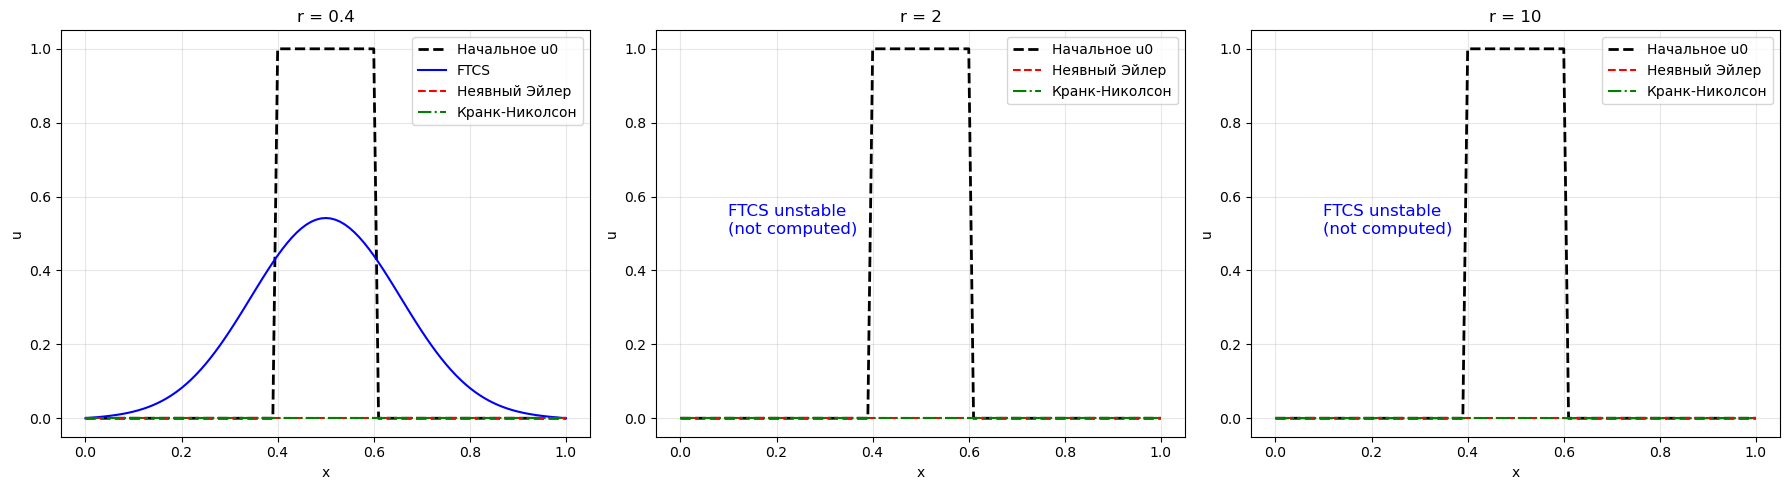

In [5]:
N = 100
T_final = 0.01
r_values = [0.4, 2, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x, dx = make_grid(N)

for ax, r in zip(axes, r_values):
    ax.plot(x, u0_step(x), 'k--', label='Начальное u0', lw=2)
    
    # FTCS работает только при r <= 0.5
    if r <= 0.5:
        _, h_ftcs = solve_heat(N, T_final, r, 'FTCS', u0_step)
        ax.plot(x, h_ftcs[-1][1], 'b-', label='FTCS')
    else:
        ax.text(0.1, 0.5, "FTCS unstable\n(not computed)", color='blue', fontsize=12)
        
    _, h_eul = solve_heat(N, T_final, r, 'Euler', u0_step)
    _, h_cn  = solve_heat(N, T_final, r, 'CN', u0_step)
    
    ax.plot(x, h_eul[-1][1], 'r--', label='Неявный Эйлер')
    ax.plot(x, h_cn[-1][1],  'g-.', label='Кранк-Николсон')
    
    ax.set_title(f"r = {r}")
    ax.set_xlabel("x")
    ax.set_ylabel("u")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Отрицательные значения и осцилляции

Безусловная устойчивость не означает отсутствие нефизических осцилляций.
Кранк-Николсон на разрыве при больших $r$ дает сильные выбросы (осцилляции Гиббса).
Строим крупным планом первые шаги по времени.

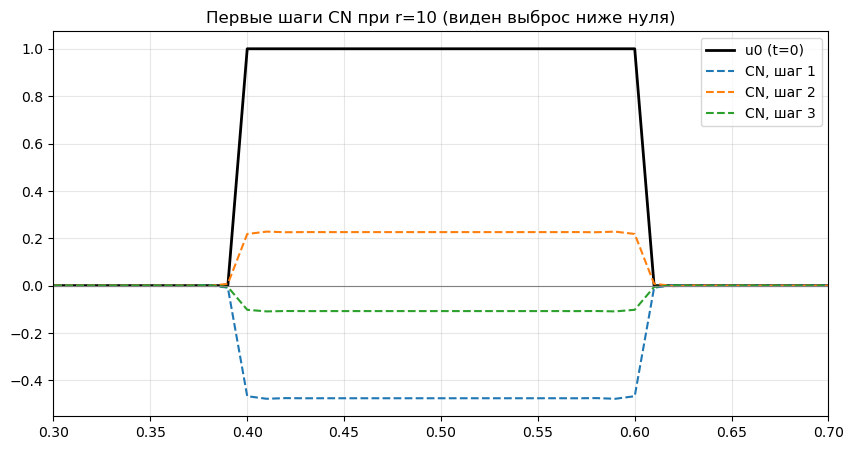

In [6]:
# Построим первые несколько временных слоев для r=10, CN
N = 100
r = 10
x, dx = make_grid(N)
dt = r * dx**2

_, h_cn = solve_heat(N, 3*dt, r, 'CN', u0_step)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, u0_step(x), 'k-', lw=2, label='u0 (t=0)')
for i in range(1, 4):
    t_i, u_i = h_cn[i]
    ax.plot(x, u_i, '--', label=f'CN, шаг {i}')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlim(0.3, 0.7)
ax.set_title("Первые шаги CN при r=10 (виден выброс ниже нуля)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Графики минимума и максимума

Строим эволюцию $\min u$ и $\max u$ во времени. У корректной схемы (без осцилляций) 
минимум должен быть $\ge 0$, а максимум $\le 1$ (принцип максимума).

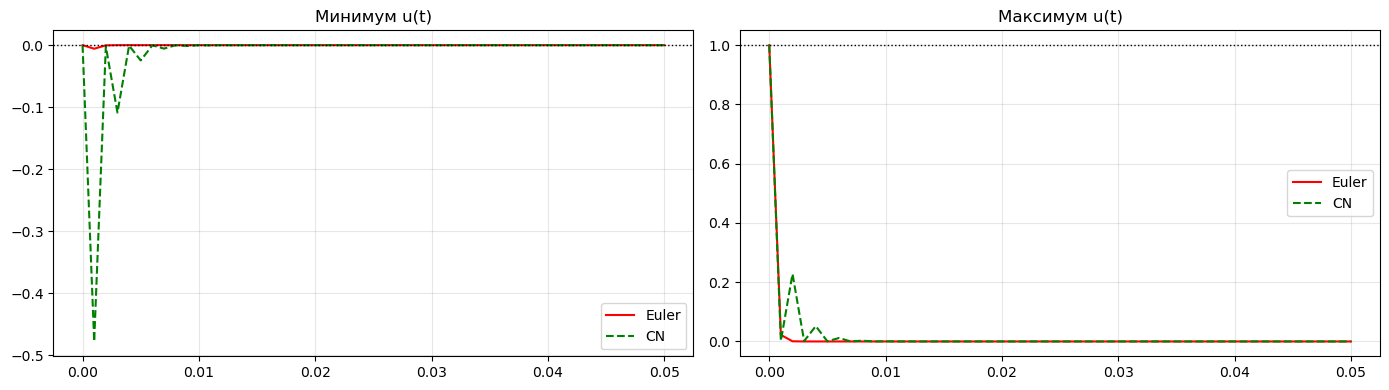

In [7]:
T_final = 0.05
r = 10

_, h_eul = solve_heat(N, T_final, r, 'Euler', u0_step)
_, h_cn  = solve_heat(N, T_final, r, 'CN', u0_step)

t_eul = np.array([h[0] for h in h_eul])
min_eul = np.array([h[1].min() for h in h_eul])
max_eul = np.array([h[1].max() for h in h_eul])

t_cn = np.array([h[0] for h in h_cn])
min_cn = np.array([h[1].min() for h in h_cn])
max_cn = np.array([h[1].max() for h in h_cn])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_eul, min_eul, 'r-', label='Euler')
axes[0].plot(t_cn, min_cn, 'g--', label='CN')
axes[0].axhline(0, color='k', lw=1, ls=':')
axes[0].set_title("Минимум u(t)")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(t_eul, max_eul, 'r-', label='Euler')
axes[1].plot(t_cn, max_cn, 'g--', label='CN')
axes[1].axhline(1, color='k', lw=1, ls=':')
axes[1].set_title("Максимум u(t)")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по желтому уровню

**Гарантирует ли безусловная устойчивость точность и отсутствие осцилляций?**
**Нет, не гарантирует.** 

1. **Точность:** Хотя неявный Эйлер и Кранк–Николсон безусловно устойчивы (они не «взрываются» даже при очень больших $r$, когда явная схема FTCS расходится), их точность сильно зависит от шага. 
   - Неявный Эйлер имеет первый порядок точности по времени $\mathcal{O}(\Delta t)$ и вносит сильную численную диффузию. При больших $r$ он чрезмерно «размазывает» ступеньку, хотя и остается монотонным.
   - Кранк–Николсон имеет второй порядок точности, но при больших $r$ он дает **нефизические осцилляции** (выбросы ниже нуля и выше единицы). На графике первых шагов видно, как решение падает до $-0.45$, что для температуры физически бессмысленно (нарушается принцип максимума).

2. **Отсутствие осцилляций:** Как видно на графике, Кранк–Николсон при $r=10$ порождает сильные выбросы вблизи разрывов (эффект Гиббса). Это происходит потому, что схема не является монотонной. Неявный Эйлер осцилляций не дает, но сильно размывает профиль.

**Итог:** Безусловная устойчивость лишь гарантирует, что решение не уйдет в бесконечность при больших шагах. Но она **не гарантирует** правильность формы профиля: можно получить либо сильное размытие (Эйлер), либо паразитные отрицательные значения (Кранк–Николсон). Для корректного моделирования разрывных начальных данных нужны либо малые шаги по времени (малые $r$), либо монотонные схемы высокого разрешения.